# Import data splitting

In [1]:
import joblib

data_split = joblib.load("../data/processed/data_split.pkl")

X_train = data_split["X_train"]
X_test = data_split["X_test"]
y_train = data_split["y_train"]
y_test = data_split["y_test"]

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

X_train: (5634, 19)
X_test : (1409, 19)


# Import Library yang diperlukan

In [2]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC


from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import RandomizedSearchCV
from jcopml.pipeline import num_pipe, cat_pipe
from jcopml.tuning import random_search_params as rsp  
import pandas as pd

#  mendefinisikan Preprocessor jcopml

In [3]:
X_train.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges'],
      dtype='str')

In [4]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 5634 entries, 4950-BDEUX to 6490-FGZAT
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            5634 non-null   str    
 1   SeniorCitizen     5634 non-null   int64  
 2   Partner           5634 non-null   str    
 3   Dependents        5634 non-null   str    
 4   tenure            5634 non-null   int64  
 5   PhoneService      5634 non-null   str    
 6   MultipleLines     5634 non-null   str    
 7   InternetService   5634 non-null   str    
 8   OnlineSecurity    5634 non-null   str    
 9   OnlineBackup      5634 non-null   str    
 10  DeviceProtection  5634 non-null   str    
 11  TechSupport       5634 non-null   str    
 12  StreamingTV       5634 non-null   str    
 13  StreamingMovies   5634 non-null   str    
 14  Contract          5634 non-null   str    
 15  PaperlessBilling  5634 non-null   str    
 16  PaymentMethod     5634 non-null   str    
 

In [5]:
preprocessor = ColumnTransformer([
    ('numerical', num_pipe(impute='median', scaling='standard'), [ 'tenure', 'MonthlyCharges', 'TotalCharges']),
    ('categorical', cat_pipe(encoder='onehot'), ['SeniorCitizen','gender','Partner', 'Dependents',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'PaperlessBilling', 'PaymentMethod']),
    ('categorical2', cat_pipe(encoder='ordinal'),['Contract'])
])

imputasi menggunkan median karena data numeriknya cenderung skewed,sehingga jika tidak cocok menggunkan mean

#  Mendefinisikan daftar model dengan parameter random search dari rsp jcopml 

kecuali DecisionTree karena jcopml tidak menyediaknnya, oleh karena itu akan diinput manual

In [6]:
models = {
    "KNN": {
        "pipeline": Pipeline([('prep', preprocessor), ('algo', KNeighborsClassifier())]),
        "params": rsp.knn_params
    },
    "SVM": {
        "pipeline": Pipeline([('prep', preprocessor), ('algo', SVC(class_weight='balanced', max_iter=5000, random_state=42))]),
        "params": rsp.svm_params  
    },
    "Logistic Regression": {
        "pipeline": Pipeline([('prep', preprocessor), ('algo', LogisticRegression(class_weight='balanced', random_state=42))]),
        "params": rsp.logreg_params
    },
     "Decision Tree": {
        "pipeline": Pipeline([('prep', preprocessor), ('algo', DecisionTreeClassifier(class_weight='balanced',random_state=42))]),
        "params": {
           'algo__max_depth': [2, 3, 4, 5, 6, 8],
           'algo__min_samples_leaf': [5, 10, 20, 50],
           'algo__ccp_alpha': [0, 0.0005, 0.001, 0.005],
           'algo__criterion': ['gini', 'entropy']
        }
    },
    "XGBoost": {
        "pipeline": Pipeline([('prep', preprocessor), ('algo', XGBClassifier(scale_pos_weight=2.77, random_state=42, n_jobs=-1))]),
        "params": rsp.xgb_params  
    },
    "Random Forest": {
        "pipeline": Pipeline([('prep', preprocessor), ('algo', RandomForestClassifier(class_weight='balanced', random_state=42))]),
        "params": rsp.rf_params   
    }
}

# looping untuk training dan evaluasi setiap model

In [7]:
best_models = {}
results = []

for name, config in models.items():
    print(f"=== Training & Random Search Tuning {name} ===")
    
    model = RandomizedSearchCV(
        config["pipeline"], 
        config["params"], 
        n_iter=50,      
        cv=5,
        scoring='f1', 
        n_jobs=1, 
        random_state=42, 
        verbose=1
    )

    model.fit(X_train, y_train)
    best_models[name] = model
    train_score = model.score(X_train, y_train)
    cv_score = model.best_score_
    test_score = model.score(X_test, y_test)
    
    print(f"Best Params: {model.best_params_}")
    print(f"Train Score: {train_score:.4f} | CV Score: {cv_score:.4f} | Test Score: {test_score:.4f}\n")
    
    results.append({
        "Model": name,
        "Best Params": model.best_params_,
        "Train Score": train_score,
        "CV Score (Val)": cv_score,
        "Test Score": test_score
    })

# 4. Tampilkan rangkuman perbandingan akhir dalam bentuk DataFrame
df_results = pd.DataFrame(results)
print("=== RANGKUMAN PERBANDINGAN AKURASI MODEL ===")
print(df_results[["Model", "Train Score", "CV Score (Val)", "Test Score"]])

=== Training & Random Search Tuning KNN ===
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Params: {'algo__n_neighbors': 37, 'algo__p': np.float64(1.9717120953891039), 'algo__weights': 'uniform'}
Train Score: 0.6217 | CV Score: 0.6102 | Test Score: 0.5992

=== Training & Random Search Tuning SVM ===
Fitting 5 folds for each of 50 candidates, totalling 250 fits


c:\Users\MyBook Hype\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
c:\Users\MyBook Hype\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
c:\Users\MyBook Hype\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
c:\Users\MyBook Hype\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScale

Best Params: {'algo__C': np.float64(43.00001586162609), 'algo__gamma': np.float64(0.015570196345516615)}
Train Score: 0.6497 | CV Score: 0.6223 | Test Score: 0.5890

=== Training & Random Search Tuning Logistic Regression ===
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Params: {'algo__C': np.float64(0.39054412752107937), 'algo__fit_intercept': True}
Train Score: 0.6327 | CV Score: 0.6324 | Test Score: 0.6119

=== Training & Random Search Tuning Decision Tree ===
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Params: {'algo__min_samples_leaf': 20, 'algo__max_depth': 6, 'algo__criterion': 'entropy', 'algo__ccp_alpha': 0.0005}
Train Score: 0.6466 | CV Score: 0.6248 | Test Score: 0.6154

=== Training & Random Search Tuning XGBoost ===
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Params: {'algo__colsample_bytree': np.float64(0.33480426100754257), 'algo__gamma': 10, 'algo__learning_rate': np.float64(0.17853354619828216), 'algo_

=== Feature Importance untuk Model: KNN ===


=== Feature Importance untuk Model: SVM ===


=== Feature Importance untuk Model: Logistic Regression ===


=== Feature Importance untuk Model: Decision Tree ===


=== Feature Importance untuk Model: XGBoost ===


=== Feature Importance untuk Model: Random Forest ===




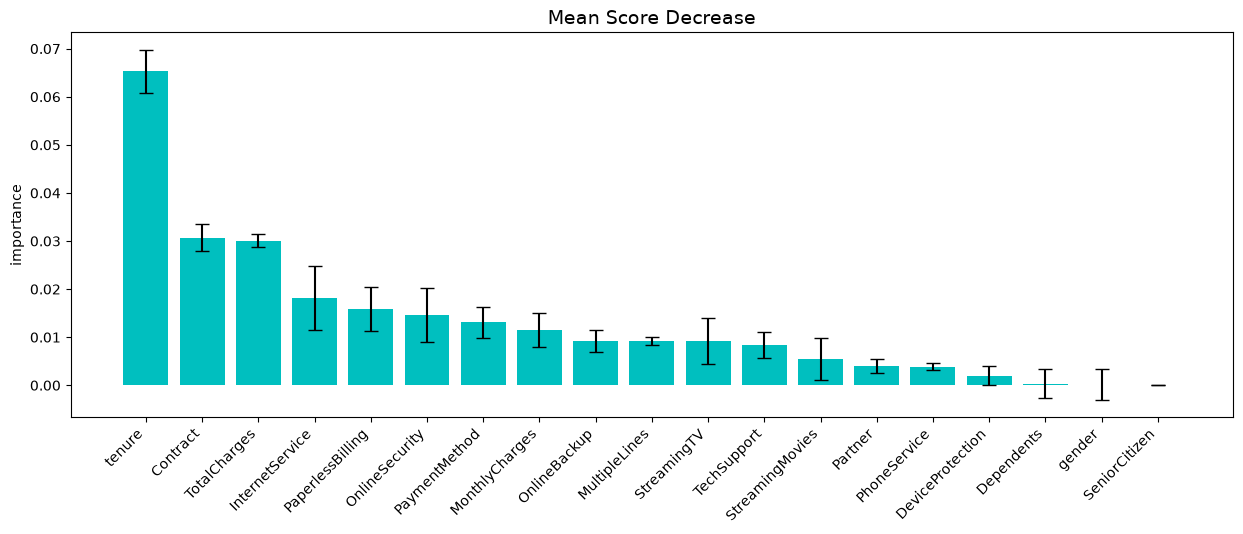

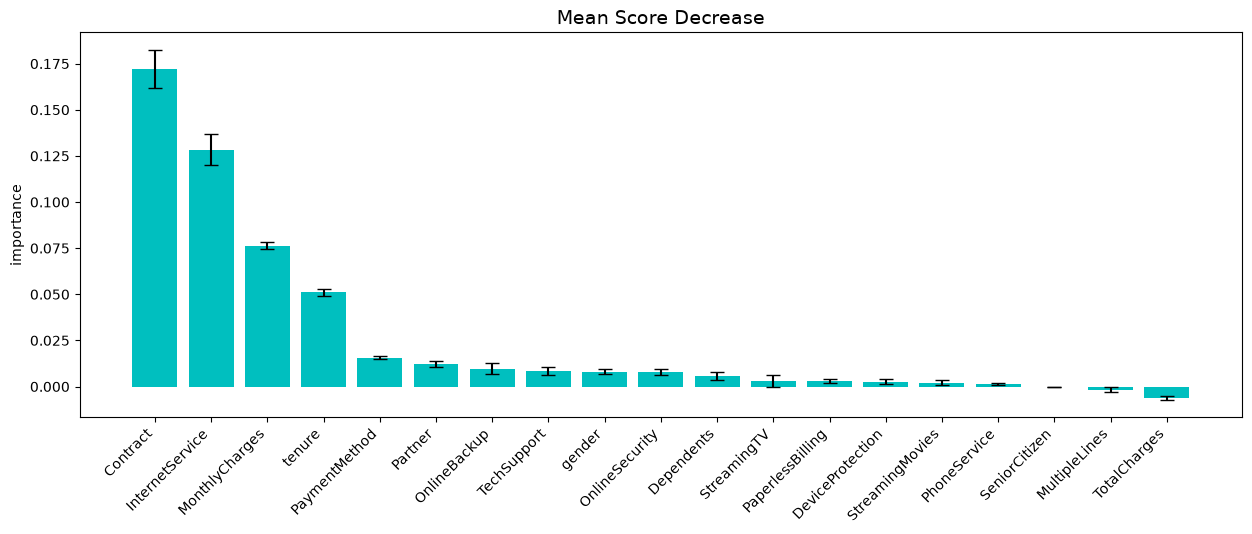

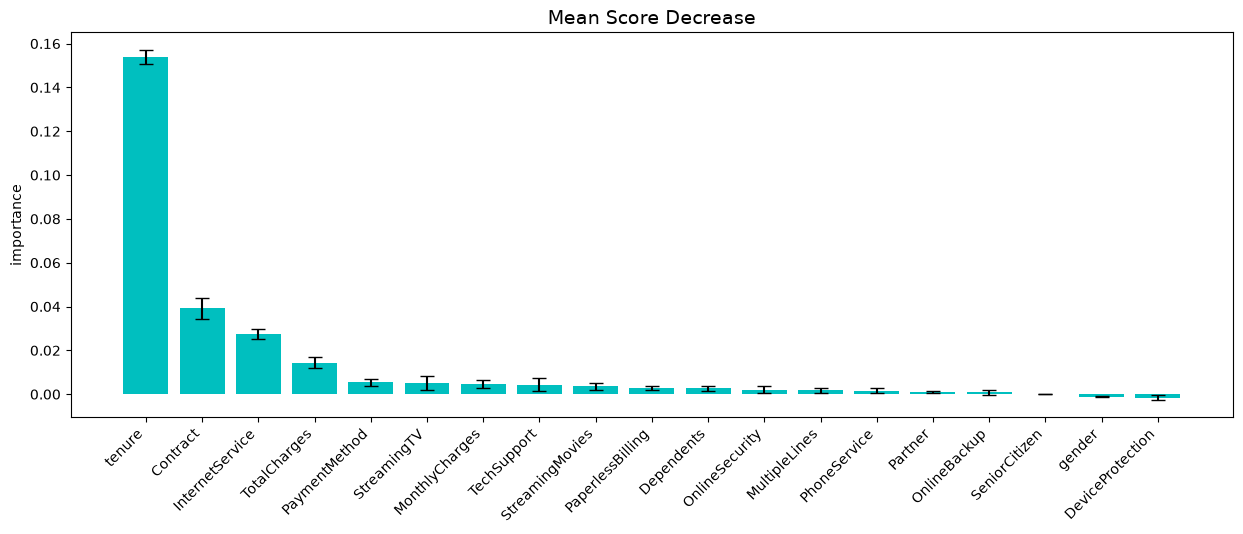

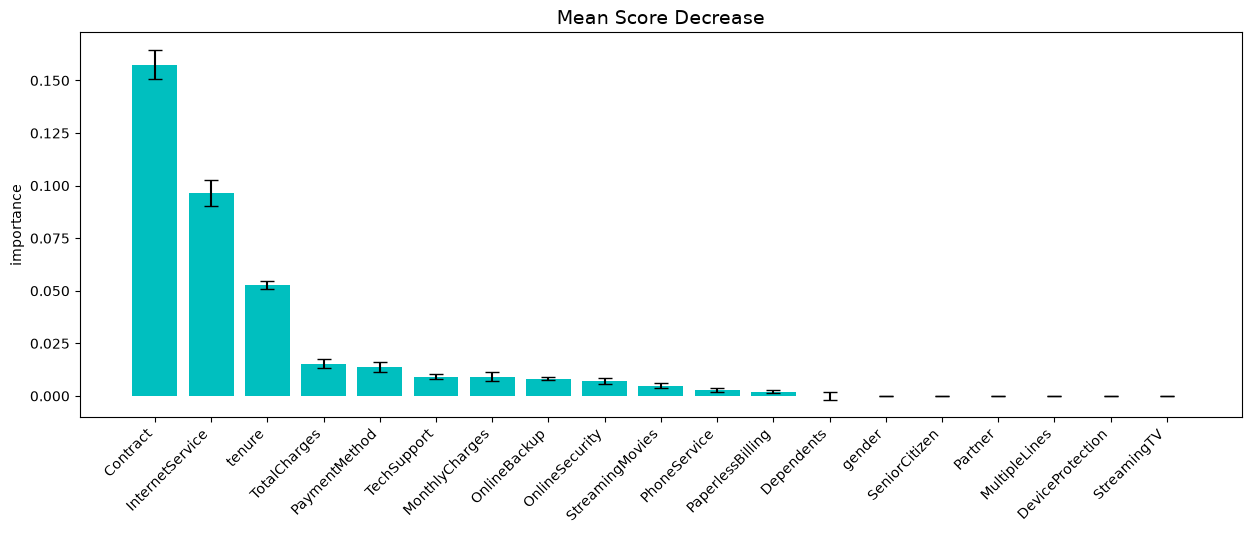

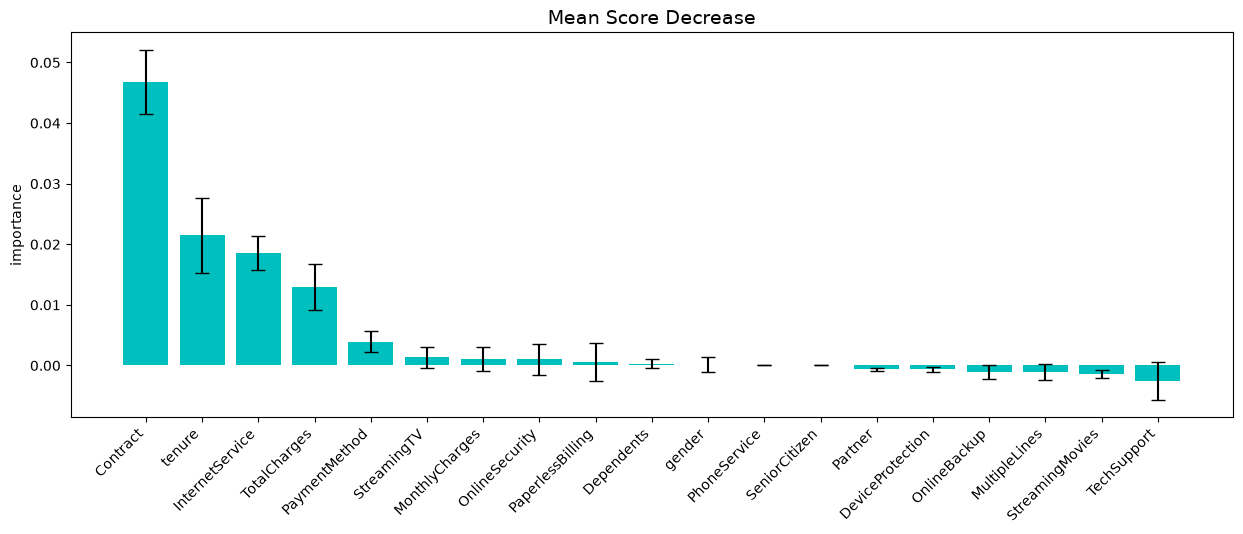

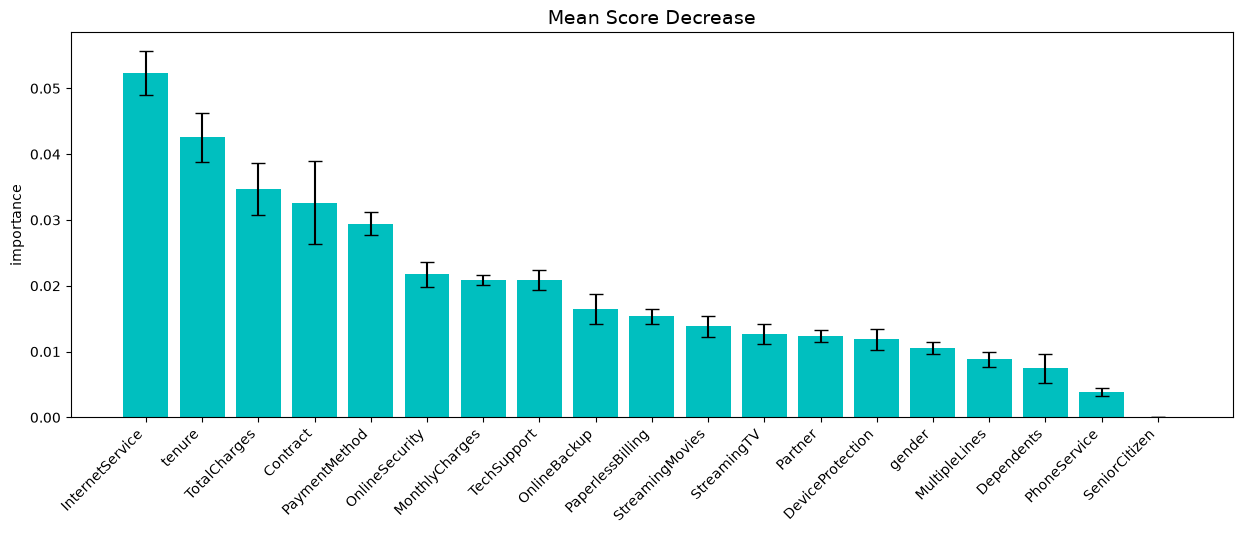

In [8]:
from jcopml.feature_importance import mean_score_decrease

# Looping melalui setiap model terbaik yang sudah disimpan sebelumnya
for name, model in best_models.items():
    print(f"=== Feature Importance untuk Model: {name} ===")
    
    # Memanggil fungsi mean_score_decrease untuk setiap model
    df_imp = mean_score_decrease(X_train, y_train, model, plot=True)
    
    # Jika Anda ingin melihat dataframe-nya juga
    # display(df_imp)
    print("\n")

# Save Model

In [9]:
import joblib
joblib.dump(best_models, "../models/best_models_1.pkl")

['../models/best_models_1.pkl']

# Evaluasi

In [10]:
from jcopml.plot import plot_classification_report, plot_confusion_matrix, plot_roc_curve, plot_pr_curve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score,
    accuracy_score, precision_score, recall_score, f1_score
)

In [11]:
def get_score(model, X):
    """Skor kelas positif; SVM tanpa probability=True memakai decision_function."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def hitung_metrik(model, X, y):
    y_pred = model.predict(X)
    y_score = get_score(model, X)
    return {
        "Accuracy": accuracy_score(y, y_pred),
        "Precision": precision_score(y, y_pred),
        "Recall": recall_score(y, y_pred),
        "F1": f1_score(y, y_pred),
        "ROC-AUC": roc_auc_score(y, y_score),
        "AP": average_precision_score(y, y_score),
    }

rows = []
for name, model in best_models.items():
    tr = hitung_metrik(model, X_train, y_train)
    te = hitung_metrik(model, X_test, y_test)
    row = {"Model": name}
    for k in tr:
        row[f"{k} Train"] = tr[k]
        row[f"{k} Test"] = te[k]
    rows.append(row)

df_compare = pd.DataFrame(rows).set_index("Model").round(4)

# Ringkasan test, diurutkan berdasarkan AP
kolom_test = [c for c in df_compare.columns if c.endswith("Test")]
print("=== RINGKASAN TEST ===")
print(df_compare[kolom_test].sort_values("AP Test", ascending=False))

# Gap train - test (indikasi overfitting)
gap = pd.DataFrame({
    "Gap F1": df_compare["F1 Train"] - df_compare["F1 Test"],
    "Gap ROC-AUC": df_compare["ROC-AUC Train"] - df_compare["ROC-AUC Test"],
    "Gap AP": df_compare["AP Train"] - df_compare["AP Test"],
}).round(4)
print("\n=== GAP TRAIN - TEST ===")
print(gap)

# Classification report per model
for name, model in best_models.items():
    print(f"\n===== {name} | Train =====")
    print(classification_report(y_train, model.predict(X_train), digits=2))
    print(f"===== {name} | Test =====")
    print(classification_report(y_test, model.predict(X_test), digits=2))

=== RINGKASAN TEST ===
                     Accuracy Test  Precision Test  Recall Test  F1 Test  \
Model                                                                      
XGBoost                     0.7424          0.5094       0.7968   0.6215   
Random Forest               0.7559          0.5270       0.7834   0.6301   
Logistic Regression         0.7353          0.5009       0.7861   0.6119   
Decision Tree               0.7374          0.5034       0.7914   0.6154   
KNN                         0.7921          0.6134       0.5856   0.5992   
SVM                         0.7197          0.4821       0.7567   0.5890   

                     ROC-AUC Test  AP Test  
Model                                       
XGBoost                    0.8461   0.6535  
Random Forest              0.8394   0.6473  
Logistic Regression        0.8404   0.6327  
Decision Tree              0.8362   0.6271  
KNN                        0.8314   0.6041  
SVM                        0.7770   0.4743  

=== GAP

## Confusion Matrix

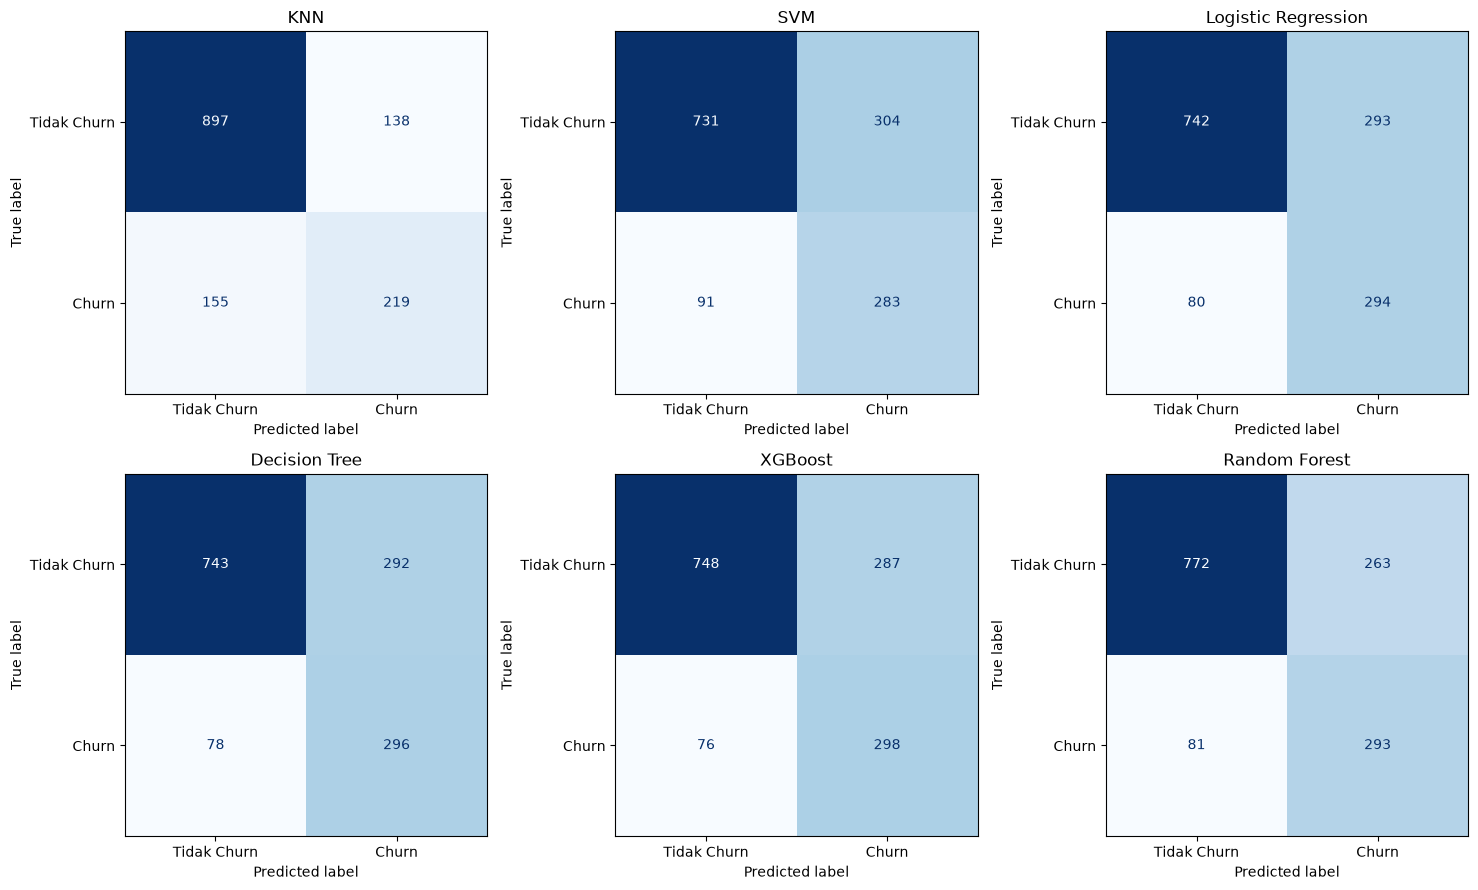

In [12]:
n = len(best_models)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, (name, model) in zip(axes, best_models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Tidak Churn", "Churn"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(name)

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## ROC and PR kurve

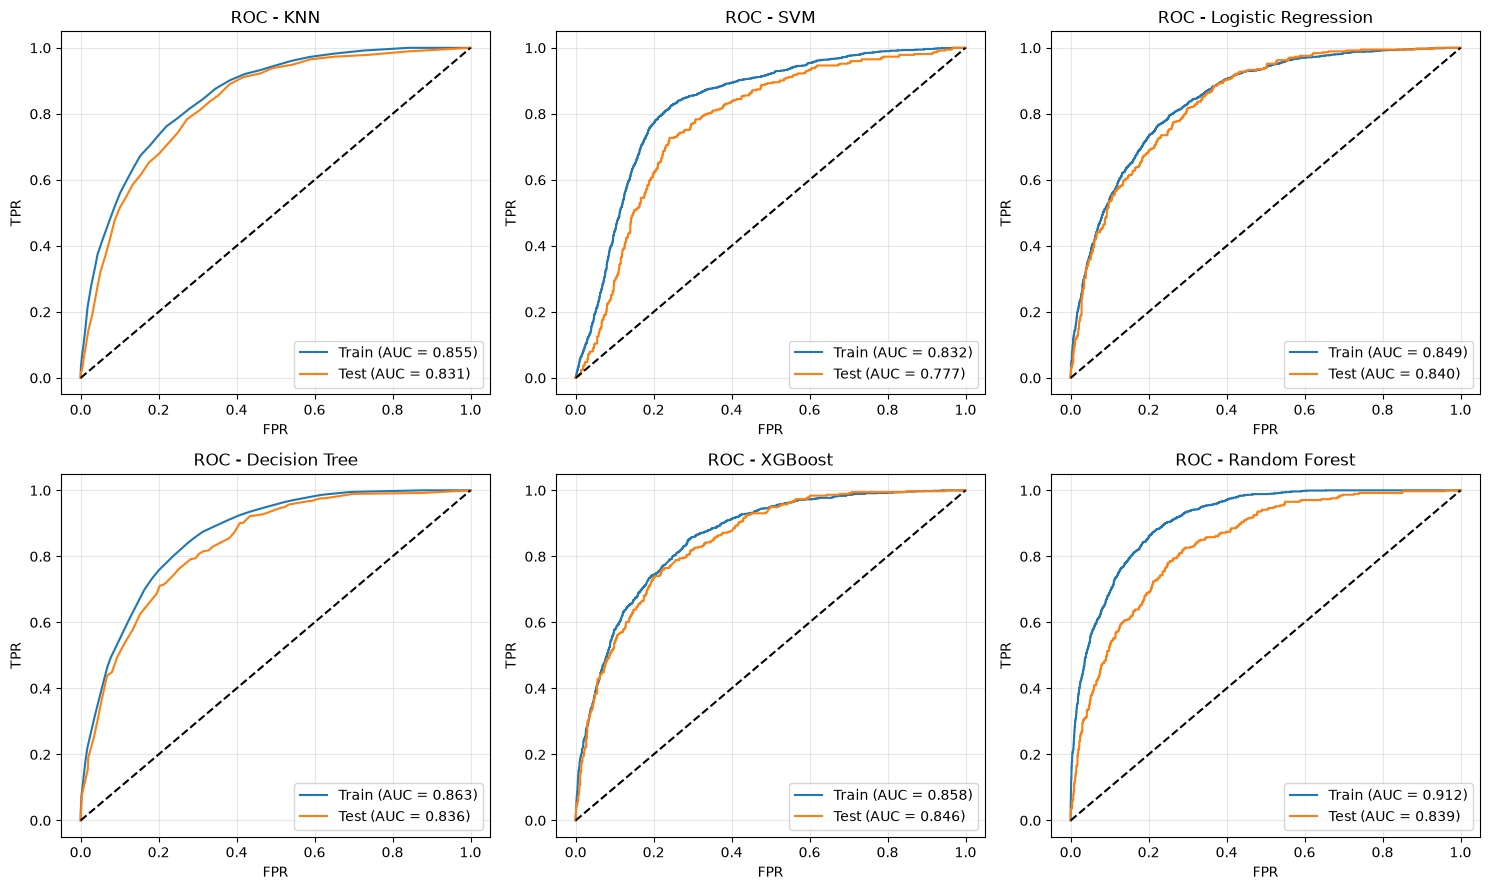

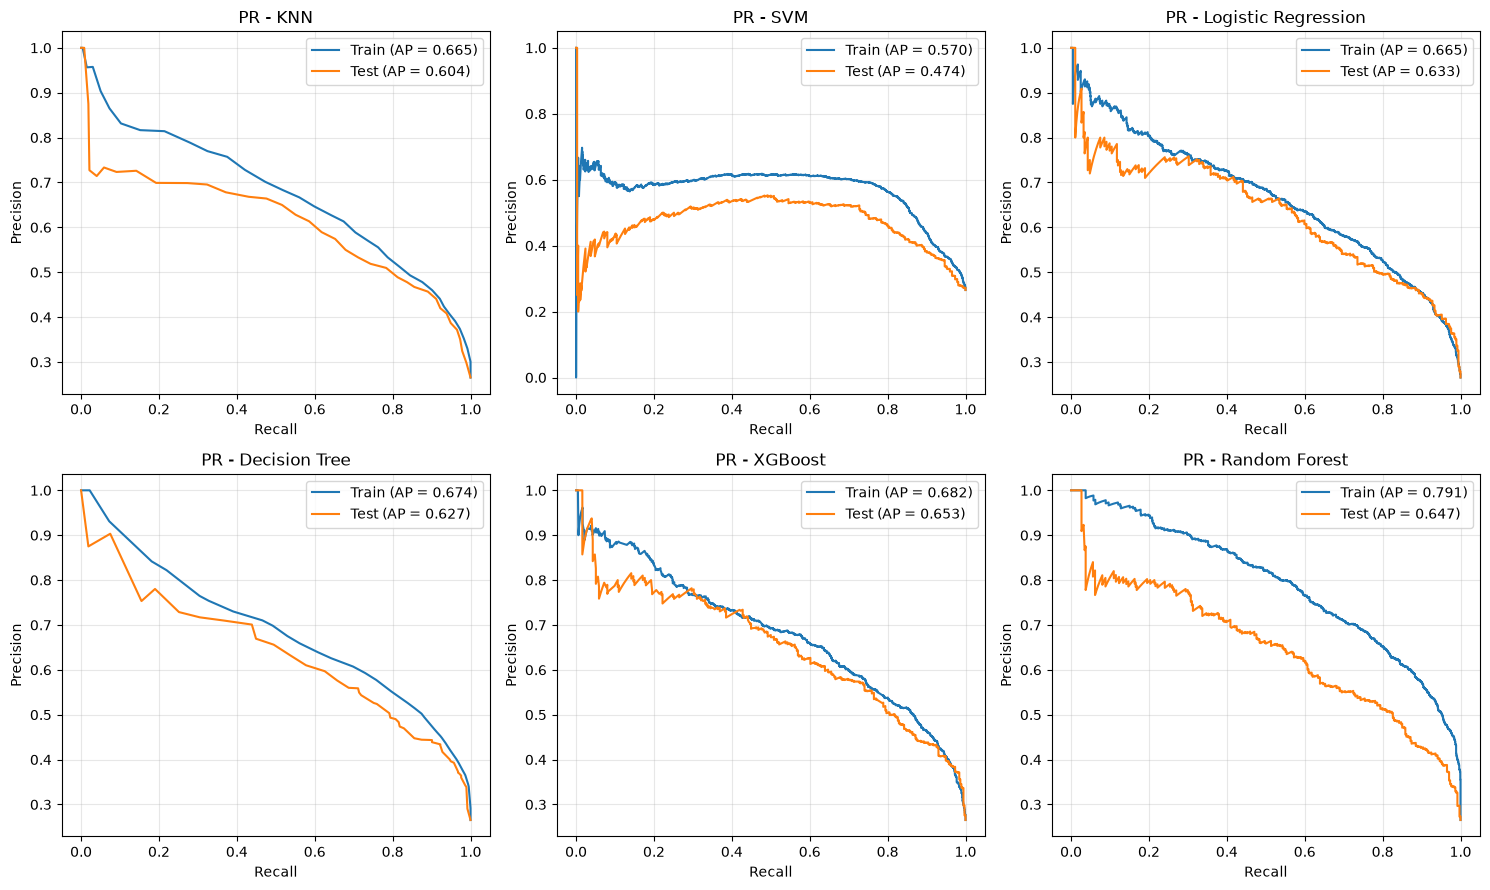

In [13]:
n = len(best_models)
ncols = 3
nrows = int(np.ceil(n / ncols))

# ROC: train vs test per model
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, (name, model) in zip(axes, best_models.items()):
    for X, y, label, color in [(X_train, y_train, "Train", "tab:blue"),
                               (X_test, y_test, "Test", "tab:orange")]:
        s = get_score(model, X)
        fpr, tpr, _ = roc_curve(y, s)
        ax.plot(fpr, tpr, color=color, label=f"{label} (AUC = {roc_auc_score(y, s):.3f})")
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_title(f"ROC - {name}")
    ax.set_xlabel("FPR")
    ax.set_ylabel("TPR")
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

# PR: train vs test per model
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, (name, model) in zip(axes, best_models.items()):
    for X, y, label, color in [(X_train, y_train, "Train", "tab:blue"),
                               (X_test, y_test, "Test", "tab:orange")]:
        s = get_score(model, X)
        prec, rec, _ = precision_recall_curve(y, s)
        ax.plot(rec, prec, color=color, label=f"{label} (AP = {average_precision_score(y, s):.3f})")
    ax.set_title(f"PR - {name}")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()